<a href="https://colab.research.google.com/github/adhilmohd/heart_disease_prediction_model/blob/main/Heart_Disease_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# --- Cell 1: Import Libraries ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
import joblib

print("All libraries imported successfully!")
print(f"scikit-learn version: {__import__('sklearn').__version__}")
print(f"pandas version: {pd.__version__}")

All libraries imported successfully!
scikit-learn version: 1.6.1
pandas version: 2.2.3


In [2]:
# --- Cell 2: Load Dataset ---
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

column_names = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs',
    'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'
]

df = pd.read_csv(url, names=column_names, na_values='?')

print(f"Dataset shape: {df.shape}")
print(f"\nFirst 5 rows:")
print(df.head())
print(f"\nData types:")
print(df.dtypes)

Dataset shape: (303, 14)

First 5 rows:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       2  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object


In [3]:
# --- Cell 3: Initial Exploration ---
print(f"Missing values per column:")
print(df.isnull().sum())
print(f"\nTarget distribution (original):")
print(df['target'].value_counts())

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Target distribution (original):
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [4]:
# --- Cell 4: Binarize Target ---
df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

print(f"Binary target distribution:")
print(df['target'].value_counts())
print(f"\nDisease present: {df['target'].sum()}")
print(f"No disease: {(df['target'] == 0).sum()}")

Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64

Disease present: 139
No disease: 164


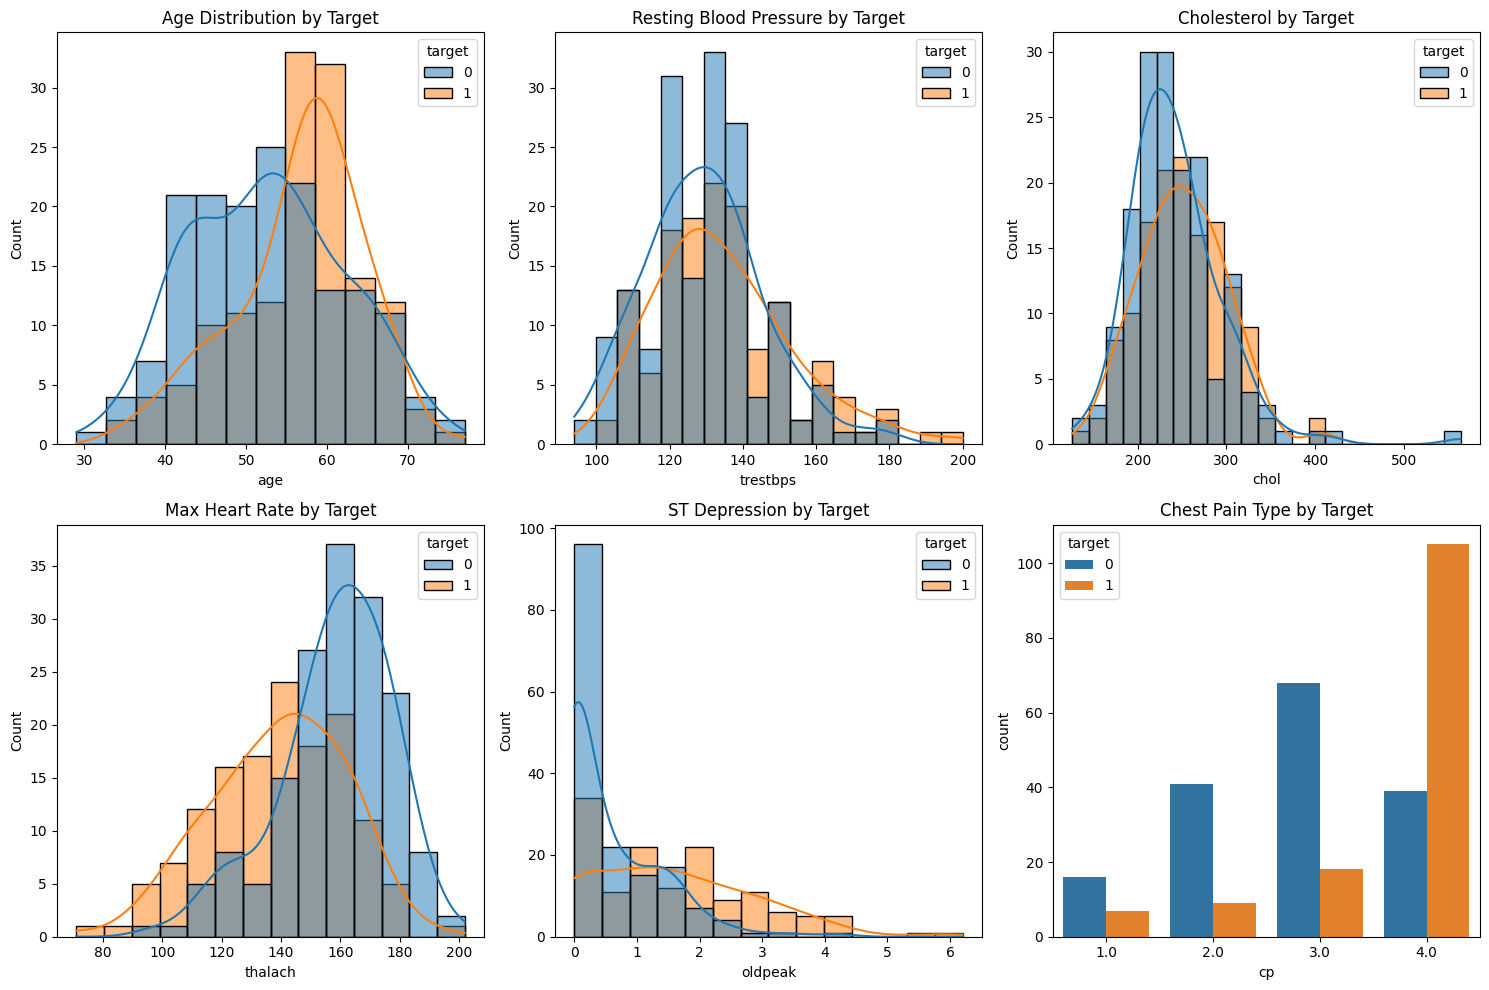

In [5]:
# --- Cell 5: EDA - Distribution Plots ---
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

sns.histplot(data=df, x='age', hue='target', kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Age Distribution by Target')

sns.histplot(data=df, x='trestbps', hue='target', kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Resting Blood Pressure by Target')

sns.histplot(data=df, x='chol', hue='target', kde=True, ax=axes[0, 2])
axes[0, 2].set_title('Cholesterol by Target')

sns.histplot(data=df, x='thalach', hue='target', kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Max Heart Rate by Target')

sns.histplot(data=df, x='oldpeak', hue='target', kde=True, ax=axes[1, 1])
axes[1, 1].set_title('ST Depression by Target')

sns.countplot(data=df, x='cp', hue='target', ax=axes[1, 2])
axes[1, 2].set_title('Chest Pain Type by Target')

plt.tight_layout()
plt.show()

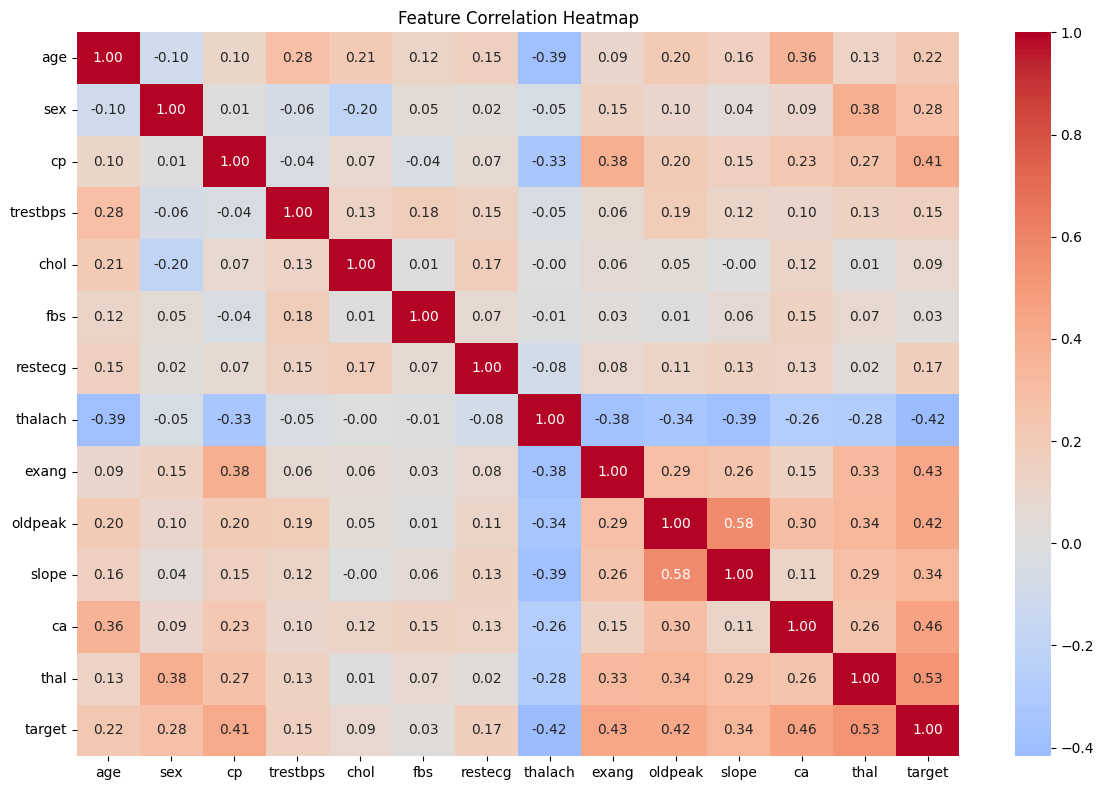

In [6]:
# --- Cell 6: EDA - Correlation Heatmap ---
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

In [7]:

# Run this in a new cell to see the exact ranking of features
df.corr(numeric_only=True)['target'].sort_values(ascending=False)



,target
target,1.000000
thal,0.525689
ca,0.460442
exang,0.431894
oldpeak,0.424510
cp,0.414446
slope,0.339213
sex,0.276816
age,0.223120
restecg,0.169202


In [8]:
# --- Cell 7: Handle Missing Values ---
print(f"Missing values before cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

df['ca'] = df['ca'].fillna(df['ca'].median())
df['thal'] = df['thal'].fillna(df['thal'].median())

print(f"\nTotal missing values after cleaning: {df.isnull().sum().sum()}")

Missing values before cleaning:
ca      4
thal    2
dtype: int64

Total missing values after cleaning: 0


In [9]:
# --- Cell 8: Train/Test Split ---
X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")
print(f"\nTraining target distribution:")
print(y_train.value_counts())

Training set size: 242
Test set size: 61

Training target distribution:
target
0    131
1    111
Name: count, dtype: int64


In [10]:
# --- Cell 9: Train Logistic Regression ---
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

lr_pipeline.fit(X_train, y_train)
lr_predictions = lr_pipeline.predict(X_test)

print("Logistic Regression Results:")
print(f"Accuracy: {accuracy_score(y_test, lr_predictions):.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, lr_predictions, target_names=['No Disease', 'Disease']))

Logistic Regression Results:
Accuracy: 0.8689

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.93      0.82      0.87        33
     Disease       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



In [11]:
# --- Cell 10: Train Random Forest ---
rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

rf_pipeline.fit(X_train, y_train)
rf_predictions = rf_pipeline.predict(X_test)

print("Random Forest Results:")
print(f"Accuracy: {accuracy_score(y_test, rf_predictions):.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, rf_predictions, target_names=['No Disease', 'Disease']))

Random Forest Results:
Accuracy: 0.8852

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.96      0.82      0.89        33
     Disease       0.82      0.96      0.89        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.90      0.89      0.89        61



In [12]:
# --- Cell 11: Cross-Validation Comparison ---
lr_cv_scores = cross_val_score(lr_pipeline, X, y, cv=5, scoring='accuracy')
rf_cv_scores = cross_val_score(rf_pipeline, X, y, cv=5, scoring='accuracy')

print("5-Fold Cross-Validation Results:")
print(f"\nLogistic Regression: {lr_cv_scores.mean():.4f} (+/- {lr_cv_scores.std():.4f})")
print(f"Random Forest:       {rf_cv_scores.mean():.4f} (+/- {rf_cv_scores.std():.4f})")

5-Fold Cross-Validation Results:

Logistic Regression: 0.8283 (+/- 0.0360)
Random Forest:       0.8182 (+/- 0.0390)


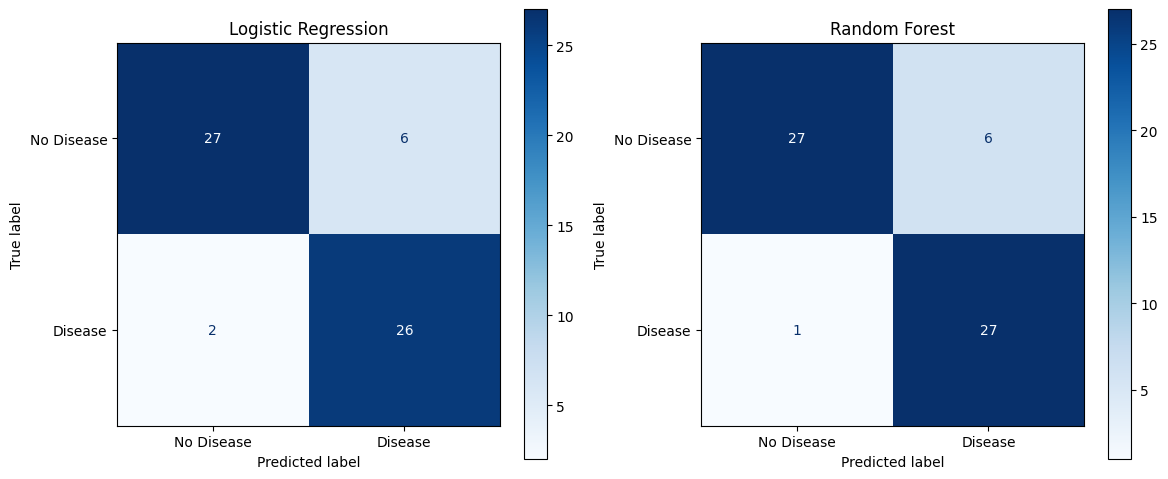

In [13]:
# --- Cell 12: Confusion Matrix Visualization ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, lr_predictions,
    display_labels=['No Disease', 'Disease'],
    ax=axes[0],
    cmap='Blues'
)
axes[0].set_title('Logistic Regression')

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_predictions,
    display_labels=['No Disease', 'Disease'],
    ax=axes[1],
    cmap='Blues'
)
axes[1].set_title('Random Forest')

plt.tight_layout()
plt.show()

In [14]:
# --- Cell 13: Save Best Model ---
best_pipeline = lr_pipeline

joblib.dump(best_pipeline, 'heart_disease_model.joblib')
print("Model saved as 'heart_disease_model.joblib'")

Model saved as 'heart_disease_model.joblib'


In [15]:
# --- Cell 14: Test Saved Model ---
loaded_model = joblib.load('heart_disease_model.joblib')

sample_patient = X_test.iloc[0:1]
prediction = loaded_model.predict(sample_patient)
probability = loaded_model.predict_proba(sample_patient)

print(f"Sample patient features:")
print(sample_patient.to_dict('records')[0])
print(f"\nPrediction: {'Disease Present' if prediction[0] == 1 else 'No Disease'}")
print(f"Probability of disease: {probability[0][1]:.4f}")

Sample patient features:
{'age': 59.0, 'sex': 1.0, 'cp': 4.0, 'trestbps': 138.0, 'chol': 271.0, 'fbs': 0.0, 'restecg': 2.0, 'thalach': 182.0, 'exang': 0.0, 'oldpeak': 0.0, 'slope': 1.0, 'ca': 0.0, 'thal': 3.0}

Prediction: No Disease
Probability of disease: 0.2177
